# Chapitre 17 - Modèles graphiques non orientés
## Cours 1 : graphes, indépendance conditionnelle et modèle gaussien

Un **modèle graphique** représente la loi jointe d'un vecteur aléatoire
$X = (X_1, \dots, X_p)$ par un **graphe** : chaque sommet est une variable, et
l'**absence** d'arête entre deux sommets signifie que les deux variables sont
**conditionnellement indépendantes** sachant toutes les autres. On obtient ainsi
une image lisible de la structure de dépendance, utile par exemple en biologie
(réseaux de protéines, de gènes).

Ce premier notebook couvre les sections 17.1 à 17.3 du livre :

1. le vocabulaire des graphes (sommets, arêtes, chemins, cliques, séparation) ;
2. l'indépendance conditionnelle et les **propriétés de Markov** d'un graphe ;
3. la factorisation d'une densité sur les cliques (théorème de Hammersley–Clifford) ;
4. le **modèle graphique gaussien** : rôle de la matrice de précision $\Theta = \Sigma^{-1}$ ;
5. l'estimation à graphe connu (**algorithme 17.1**, régressions modifiées) ;
6. l'estimation du graphe par le **graphical lasso** (**algorithme 17.2**), son chemin
   de régularisation et une reproduction de la figure 17.5 sur données simulées.

Le cas des variables binaires (modèles de Ising, machines de Boltzmann) est traité
dans le cours 2.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import ch17_graphes as g

## 1. Vocabulaire des graphes

> **Intuition.** Un graphe est un dessin fait de points (les *sommets*) reliés ou
> non par des traits (les *arêtes*). Seule compte la liste des paires reliées, pas la
> position des points sur la feuille.

**Définition (graphe non orienté).** Un graphe est un couple $G = (V, E)$ où $V$ est
un ensemble fini de **sommets** (ou nœuds) et $E$ un ensemble de paires
$\{j, k\}$ de sommets distincts, appelées **arêtes**. « Non orienté » signifie que
l'arête $\{j,k\}$ n'a pas de sens : elle relie $j$ et $k$ symétriquement.

Quelques définitions dont nous aurons besoin (avec les notations du livre) :

- $j$ et $k$ sont **adjacents** (ou **voisins**) si $\{j,k\} \in E$ ; on note $j \sim k$.
  L'ensemble des voisins de $j$ est noté $\mathcal N(j)$ et son cardinal est le
  **degré** de $j$.
- Un **chemin** est une suite de sommets $j_1, j_2, \dots, j_n$ telle que
  $j_{i-1} \sim j_i$ pour $i = 2, \dots, n$.
- Le graphe est **connexe** si deux sommets quelconques sont reliés par un chemin ;
  sinon il se découpe en **composantes connexes**.
- Le graphe est **complet** si toutes les paires de sommets sont reliées.
- Le **sous-graphe** induit par $U \subset V$ est formé des sommets de $U$ et des
  arêtes de $E$ dont les deux extrémités sont dans $U$.

**Matrice d'adjacence.** Pour calculer, on numérote les sommets $1, \dots, p$ et on
code le graphe par la matrice $A \in \{0,1\}^{p \times p}$ avec $A_{jk} = 1$ si
$j \sim k$, $0$ sinon. Elle est **symétrique** (graphe non orienté) et de diagonale
nulle (pas de boucle). Le degré de $j$ est la somme de la ligne $j$.

Construisons les quatre graphes de la figure 17.2 du livre, sur les variables
$X, Y, Z, W$ (numérotées 0, 1, 2, 3).

In [2]:
noms = ["$X$", "$Y$", "$Z$", "$W$"]
fig172 = {
    "(a)": (3, [(0, 1), (1, 2)]),
    "(b)": (4, [(0, 1), (0, 3), (1, 3)]),
    "(c)": (4, [(0, 1), (1, 2), (2, 3), (3, 0)]),
    "(d)": (4, [(0, 1), (1, 2), (2, 3)]),
}
graphes = {k: g.adjacency_from_edges(p, e) for k, (p, e) in fig172.items()}
print(graphes["(c)"].astype(int))
print("degrés de (c) :", graphes["(c)"].sum(axis=1))

[[0 1 0 1]
 [1 0 1 0]
 [0 1 0 1]
 [1 0 1 0]]
degrés de (c) : [2 2 2 2]


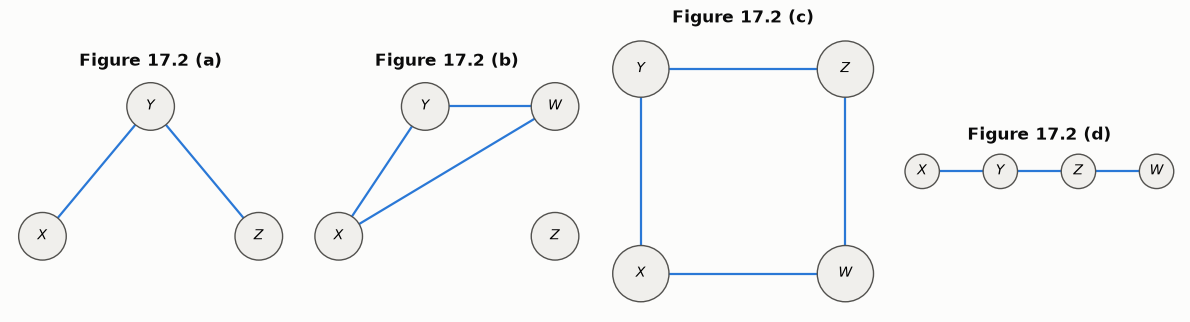

In [3]:
pos172 = {
    "(a)": np.array([[-1, -0.6], [0, 0.6], [1, -0.6]]),
    "(b)": np.array([[-1, -0.6], [-0.2, 0.6], [1, -0.6], [1, 0.6]]),
    "(c)": np.array([[-0.8, -0.8], [-0.8, 0.8], [0.8, 0.8], [0.8, -0.8]]),
    "(d)": np.array([[-1.5, 0], [-0.5, 0], [0.5, 0], [1.5, 0]]),
}
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, (k, A) in zip(axes, graphes.items()):
    g.draw_graph(A, labels=noms[:A.shape[0]], pos=pos172[k], ax=ax,
                 node_size=0.22, title="Figure 17.2 %s" % k)
plt.tight_layout()
plt.show()

Dans (a), $X, Y, Z$ forment un chemin mais pas un graphe complet ($X$ et $Z$ ne
sont pas reliés). Dans (b), $Z$ est isolé : le graphe a deux composantes connexes.

In [4]:
for k, A in graphes.items():
    print(k, "composantes connexes :", g.connected_components(A))

(a) composantes connexes : [[0, 1, 2]]
(b) composantes connexes : [[0, 1, 3], [2]]
(c) composantes connexes : [[0, 1, 2, 3]]
(d) composantes connexes : [[0, 1, 2, 3]]


### Cliques

**Définition.** Une **clique** est un ensemble de sommets deux à deux adjacents
(le sous-graphe induit est complet). Elle est **maximale** si on ne peut lui ajouter
aucun sommet sans perdre cette propriété.

> **Remarque.** Un sommet seul est une clique (triviale) ; un sommet isolé est donc
> une clique maximale à lui seul, comme $\{Z\}$ dans la figure 17.2(b).

Pour les énumérer, on utilise l'algorithme récursif de Bron–Kerbosch : on fait
grandir une clique $R$ en ajoutant un à un des sommets candidats $P$ adjacents à
tous ceux de $R$, et on déclare $R$ maximale quand plus aucun sommet (ni candidat,
ni déjà exclu $X$) ne peut l'étendre.

In [5]:
for k, A in graphes.items():
    cl = g.maximal_cliques(A)
    print(k, [{noms[i].strip("$") for i in c} for c in cl])

(a) [{'Y', 'X'}, {'Z', 'Y'}]
(b) [{'Y', 'W', 'X'}, {'Z'}]
(c) [{'Y', 'X'}, {'W', 'X'}, {'Z', 'Y'}, {'Z', 'W'}]
(d) [{'Y', 'X'}, {'Z', 'Y'}, {'Z', 'W'}]


On retrouve la liste donnée dans le livre : (a) $\{X,Y\},\{Y,Z\}$ ;
(b) $\{X,Y,W\},\{Z\}$ ; (c) les quatre côtés du carré ; (d) les trois arêtes du chemin.

## 2. Indépendance conditionnelle et propriétés de Markov

**Définition.** Soient $A, B, C$ trois (groupes de) variables aléatoires de densité
jointe $f$. On dit que $A$ est **indépendante de $B$ conditionnellement à $C$**, et on
note $A \perp B \mid C$, si pour tout $c$ (avec $f(c) > 0$)

$$
f(a, b \mid c) = f(a \mid c)\, f(b \mid c).
$$

De façon équivalente (en divisant par $f(b \mid c)$) : $f(a \mid b, c) = f(a \mid c)$ ;
une fois $C$ connue, connaître $B$ n'apporte plus rien pour prédire $A$
(voir l'exercice 17.4).

> **Intuition.** Indépendance conditionnelle et indépendance sont deux notions
> différentes. Si $X \to Y \to Z$ est une « chaîne » (par exemple $Y = X + $ bruit et
> $Z = Y + $ bruit), alors $X$ et $Z$ sont **corrélées**, mais une fois $Y$ fixée, la
> valeur de $X$ ne dit plus rien sur $Z$ : $X \perp Z \mid Y$.

Vérifions-le par simulation. Pour des variables gaussiennes, l'indépendance
conditionnelle sachant $Y$ se lit sur la **corrélation partielle** : la corrélation
entre les résidus des régressions linéaires de $X$ sur $Y$ et de $Z$ sur $Y$.

In [6]:
rng = np.random.RandomState(0)
N = 2000
x = rng.randn(N)
y = x + 0.7 * rng.randn(N)
z = y + 0.7 * rng.randn(N)


def residu(u, v):
    """Résidu de la régression linéaire (avec constante) de u sur v."""
    V = np.c_[np.ones_like(v), v]
    return u - V @ np.linalg.lstsq(V, u, rcond=None)[0]


rx, rz = residu(x, y), residu(z, y)
print("corrélation(X, Z)            = %.3f" % np.corrcoef(x, z)[0, 1])
print("corrélation partielle(X,Z|Y) = %.3f" % np.corrcoef(rx, rz)[0, 1])

corrélation(X, Z)            = 0.708
corrélation partielle(X,Z|Y) = -0.004


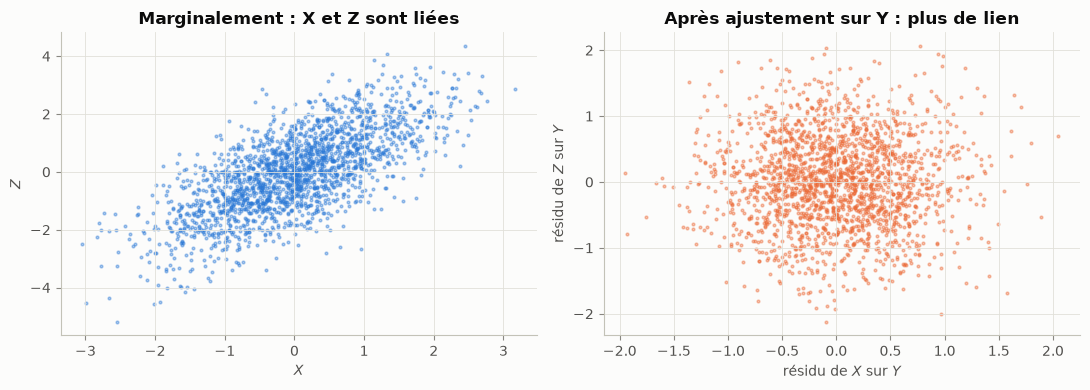

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(x, z, s=4, alpha=0.4, color=BLUE)
axes[0].set(title="Marginalement : X et Z sont liées", xlabel="$X$", ylabel="$Z$")
axes[1].scatter(rx, rz, s=4, alpha=0.4, color=ORANGE)
axes[1].set(title="Après ajustement sur Y : plus de lien",
            xlabel="résidu de $X$ sur $Y$", ylabel="résidu de $Z$ sur $Y$")
plt.tight_layout()
plt.show()

### Propriété de Markov par paires

**Définition (graphe de Markov).** Soit $G = (V,E)$ un graphe dont les sommets sont
les variables $X_1, \dots, X_p$, de loi jointe $P$. On dit que $P$ vérifie la
**propriété de Markov par paires** relativement à $G$ si (éq. (17.1) du livre)

$$
\{j,k\} \notin E \;\Longrightarrow\; X_j \perp X_k \mid X_{\text{reste}},
$$

où « reste » désigne toutes les autres variables. Dans la figure 17.2(a), on lit ainsi
$X \perp Z \mid Y$ : c'est exactement l'exemple de la chaîne simulé ci-dessus.

### Séparation et propriété de Markov globale

**Définition (séparation).** Soient $A, B, C$ trois ensembles de sommets. On dit que
$C$ **sépare** $A$ et $B$ si **tout chemin** reliant un sommet de $A$ à un sommet de
$B$ passe par un sommet de $C$. Autrement dit : si l'on efface les sommets de $C$
(et leurs arêtes), plus aucun sommet de $B$ n'est accessible depuis $A$.

Exemples (figure 17.2) : $Y$ sépare $X$ et $Z$ dans (a) et (d) ; $Z$ sépare $Y$ et
$W$ dans (d) ; dans (c), $\{X, Z\}$ sépare $Y$ et $W$ ; dans (b), $Z$ n'est relié à
rien, il est séparé de $\{X,Y,W\}$ par l'ensemble vide.

In [8]:
A = graphes["(d)"]  # X - Y - Z - W
X_, Y_, Z_, W_ = 0, 1, 2, 3
print("(d) Y sépare X et {Z, W} :", g.separates(A, [X_], [Z_, W_], [Y_]))
print("(d) Z sépare Y et W      :", g.separates(A, [Y_], [W_], [Z_]))
print("(d) W sépare X et Z      :", g.separates(A, [X_], [Z_], [W_]))
Ac = graphes["(c)"]
print("(c) {X, Z} sépare Y et W :", g.separates(Ac, [Y_], [W_], [X_, Z_]))
print("(c) {X} sépare Y et W    :", g.separates(Ac, [Y_], [W_], [X_]))
print("(b) {} sépare Z et {X,Y,W} :", g.separates(graphes["(b)"], [Z_], [X_, Y_, W_], []))

(d) Y sépare X et {Z, W} : True
(d) Z sépare Y et W      : True
(d) W sépare X et Z      : False
(c) {X, Z} sépare Y et W : True
(c) {X} sépare Y et W    : False
(b) {} sépare Z et {X,Y,W} : True


**Définition (propriété de Markov globale).** $P$ vérifie la propriété de Markov
globale relativement à $G$ si, pour tous ensembles de sommets $A, B, C$
(éq. (17.2) du livre) :

$$
C \text{ sépare } A \text{ et } B \;\Longrightarrow\; X_A \perp X_B \mid X_C .
$$

**Résultat admis.** Pour une loi de densité **strictement positive**, les propriétés
de Markov par paires et globale sont **équivalentes**. La propriété globale entraîne
clairement la propriété par paires (si $j \not\sim k$, l'ensemble « reste » sépare
$j$ et $k$) ; la réciproque est plus délicate et nous l'admettons.

> **Intérêt pratique.** On peut déduire du graphe beaucoup plus d'indépendances que
> les seules relations par paires. Dans la figure 17.2(d), la propriété par paires
> donne $X \perp Z \mid \{Y, W\}$ ; mais comme $Y$ sépare $X$ de $\{Z, W\}$, la propriété
> globale donne aussi $X \perp Z \mid Y$ et $X \perp W \mid Y$, et de même
> $Y \perp W \mid Z$. Le conditionnement porte sur **moins** de variables.

La cellule suivante énumère, pour chaque paire non adjacente du graphe (d), les
ensembles séparateurs **minimaux** (aucun sous-ensemble strict ne sépare encore).

In [9]:
from itertools import combinations


def separateurs_minimaux(A, j, k):
    """Ensembles minimaux (pour l'inclusion) séparant j et k."""
    autres = [v for v in range(A.shape[0]) if v not in (j, k)]
    seps = [set(C) for r in range(len(autres) + 1) for C in combinations(autres, r)
            if g.separates(A, [j], [k], C)]
    return [C for C in seps if not any(D < C for D in seps)]


lettres = "XYZW"
for j, k in combinations(range(4), 2):
    if not A[j, k]:
        for C in separateurs_minimaux(A, j, k):
            print("%s ⊥ %s | {%s}" % (lettres[j], lettres[k], ", ".join(lettres[c] for c in sorted(C))))

X ⊥ Z | {Y}
X ⊥ W | {Y}
X ⊥ W | {Z}
Y ⊥ W | {Z}


Vérifions ces indépendances sur un modèle gaussien de graphe (d) : nous construisons
une matrice de précision $\Theta$ dont les zéros correspondent aux arêtes absentes (le
lien entre zéros de $\Theta$ et indépendance conditionnelle est démontré en section 4),
puis nous calculons des corrélations partielles empiriques.

In [10]:
rng = np.random.RandomState(1)
Theta_d = g.make_sparse_precision(A, rng)
Xd = rng.randn(20000, 4) @ np.linalg.cholesky(np.linalg.inv(Theta_d)).T


def corr_partielle(X, j, k, C):
    """Corrélation empirique entre résidus de X_j et X_k régressés sur X_C."""
    Z = np.c_[np.ones(len(X)), X[:, list(C)]]
    rj = X[:, j] - Z @ np.linalg.lstsq(Z, X[:, j], rcond=None)[0]
    rk = X[:, k] - Z @ np.linalg.lstsq(Z, X[:, k], rcond=None)[0]
    return np.corrcoef(rj, rk)[0, 1]


for (j, k, C) in [(0, 2, []), (0, 2, [1]), (0, 3, [1]), (1, 3, [2]), (0, 3, [2])]:
    print("corr(%s, %s | {%s}) = %+.3f" % (lettres[j], lettres[k],
          ",".join(lettres[c] for c in C), corr_partielle(Xd, j, k, C)))

corr(X, Z | {}) = -0.398
corr(X, Z | {Y}) = -0.002
corr(X, W | {Y}) = -0.006
corr(Y, W | {Z}) = -0.007
corr(X, W | {Z}) = -0.010


Les corrélations partielles conditionnées par un séparateur sont nulles (aux
fluctuations d'échantillonnage près, de l'ordre de $1/\sqrt{N} \approx 0{,}007$) ; en
revanche $X$ et $Z$ sont corrélées marginalement, et conditionner $X, W$ par $Z$ (qui
ne les sépare pas) ne suffit pas.

## 3. Factorisation sur les cliques

Une densité $f$ sur un graphe de Markov $G$ peut s'écrire comme un produit de
fonctions positives portant chacune sur une clique maximale (éq. (17.3)–(17.4)) :

$$
f(x) = \frac{1}{Z} \prod_{C \in \mathcal C} \psi_C(x_C),
\qquad
Z = \sum_{x \in \mathcal X} \prod_{C \in \mathcal C} \psi_C(x_C),
$$

où $\mathcal C$ est l'ensemble des cliques maximales. Les $\psi_C > 0$ sont les
**potentiels de clique** : ce ne sont pas des densités, mais des « affinités » qui
donnent plus de poids à certaines configurations $x_C$. La constante $Z$, appelée
**fonction de partition**, assure que les probabilités somment à 1 (intégrale à la
place de la somme dans le cas continu).

**Théorème de Hammersley–Clifford (admis).** Pour une loi strictement positive, $f$
vérifie les propriétés de Markov relativement à $G$ si et seulement si elle se
factorise comme ci-dessus sur les cliques de $G$.

Un sens est facile dans un cas simple. Sur la chaîne $X - Y - Z$ (cliques $\{X,Y\}$ et
$\{Y,Z\}$), si $f(x,y,z) = \psi_1(x,y)\psi_2(y,z)/Z$, alors

$$
f(x, z \mid y) = \frac{\psi_1(x,y)\psi_2(y,z)}{\sum_{x',z'} \psi_1(x',y)\psi_2(y,z')}
= \frac{\psi_1(x,y)}{\sum_{x'}\psi_1(x',y)} \cdot \frac{\psi_2(y,z)}{\sum_{z'}\psi_2(y,z')},
$$

car la somme double se factorise ; c'est un produit d'une fonction de $x$ et d'une
fonction de $z$ : $X \perp Z \mid Y$. Vérifions-le numériquement avec des potentiels
binaires tirés au hasard.

In [11]:
rng = np.random.RandomState(2)
psi1 = rng.uniform(0.2, 3, size=(2, 2))   # psi1[x, y]
psi2 = rng.uniform(0.2, 3, size=(2, 2))   # psi2[y, z]
f = np.einsum("xy,yz->xyz", psi1, psi2)
Zpart = f.sum()
f /= Zpart
print("fonction de partition Z = %.4f" % Zpart)
for yv in (0, 1):
    fxz = f[:, yv, :] / f[:, yv, :].sum()           # f(x, z | y)
    produit = np.outer(fxz.sum(1), fxz.sum(0))      # f(x | y) f(z | y)
    print("y = %d : max |f(x,z|y) - f(x|y)f(z|y)| = %.1e" % (yv, np.abs(fxz - produit).max()))
print("X et Z marginalement indépendantes ?",
      np.allclose(f.sum(1), np.outer(f.sum((1, 2)), f.sum((0, 1)))))

fonction de partition Z = 12.4847
y = 0 : max |f(x,z|y) - f(x|y)f(z|y)| = 2.8e-17
y = 1 : max |f(x,z|y) - f(x|y)f(z|y)| = 1.1e-16
X et Z marginalement indépendantes ? False


### Un graphe ne fixe pas l'ordre des interactions

Sur le graphe complet à trois sommets (figure 17.3), les deux lois (éq. (17.5))

$$
f^{(2)}(x,y,z) = \tfrac{1}{Z}\psi(x,y)\psi(x,z)\psi(y,z),
\qquad
f^{(3)}(x,y,z) = \tfrac{1}{Z}\psi(x,y,z)
$$

ont le même graphe (aucune indépendance conditionnelle), mais la première ne contient
que des interactions **d'ordre deux** (entre paires) et a moins de paramètres : avec
des variables binaires, $3 \times 4 = 12$ valeurs de potentiels contre $8$ pour un
potentiel général à trois variables, mais une fois les redondances retirées il reste
$6$ paramètres libres pour $f^{(2)}$ contre $7$ pour $f^{(3)}$.

Dans la suite, comme le livre, on se restreint aux **graphes de Markov par paires** :
un potentiel par arête, interactions d'ordre au plus deux.

## 4. Le modèle graphique gaussien

On suppose désormais $X \sim \mathcal N_p(\mu, \Sigma)$ avec $\Sigma$ définie positive.
On note $\Theta = \Sigma^{-1}$ la **matrice de précision**. La densité s'écrit

$$
f(x) = (2\pi)^{-p/2} (\det \Theta)^{1/2}
\exp\Big(-\tfrac12 (x-\mu)^T \Theta (x-\mu)\Big)
= \text{cste} \times \prod_{j} e^{-\frac12 \theta_{jj}(x_j-\mu_j)^2}
\prod_{j<k} e^{-\theta_{jk}(x_j-\mu_j)(x_k-\mu_k)} .
$$

C'est un produit de potentiels portant sur des **paires** : la loi gaussienne
définit automatiquement un graphe de Markov par paires, dont les arêtes sont les
paires $(j,k)$ avec $\theta_{jk} \neq 0$.

### Loi conditionnelle d'une variable sachant les autres

Partageons $X = (Z, Y)$ avec $Z = (X_1, \dots, X_{p-1})$ et $Y = X_p$, et découpons
$\Sigma$ et $\Theta$ de la même façon (éq. (17.7)) :

$$
\Sigma = \begin{pmatrix} \Sigma_{ZZ} & \sigma_{ZY} \\ \sigma_{ZY}^T & \sigma_{YY}\end{pmatrix},
\qquad
\Theta = \begin{pmatrix} \Theta_{ZZ} & \theta_{ZY} \\ \theta_{ZY}^T & \theta_{YY}\end{pmatrix}.
$$

**Étape 1 : la loi de $Y$ sachant $Z = z$.** À $z$ fixé, la densité conditionnelle est
proportionnelle à la densité jointe vue comme fonction de $y$. En développant la
forme quadratique et en ne gardant que les termes qui dépendent de $y$ :

$$
\log f(y \mid z) = -\tfrac12\Big[\theta_{YY}(y-\mu_Y)^2 + 2 (y-\mu_Y)\,\theta_{ZY}^T(z-\mu_Z)\Big] + \text{cste}.
$$

On complète le carré : $\theta_{YY}\big(y - \mu_Y + \theta_{ZY}^T(z-\mu_Z)/\theta_{YY}\big)^2$ + termes sans $y$. C'est donc une loi normale :

$$
Y \mid Z = z \;\sim\; \mathcal N\Big(\mu_Y - \tfrac{1}{\theta_{YY}}\theta_{ZY}^T (z-\mu_Z),\; \tfrac{1}{\theta_{YY}}\Big).
$$

**Étape 2 : lien avec $\Sigma$ (inverse par blocs).** Écrivons la dernière colonne de
$\Sigma\Theta = I$ :

$$
\begin{aligned}
\Sigma_{ZZ}\theta_{ZY} + \sigma_{ZY}\theta_{YY} &= 0
&&\Longrightarrow\quad \theta_{ZY} = -\theta_{YY}\,\Sigma_{ZZ}^{-1}\sigma_{ZY} \quad\text{(éq. (17.8))},\\
\sigma_{ZY}^T\theta_{ZY} + \sigma_{YY}\theta_{YY} &= 1
&&\Longrightarrow\quad \theta_{YY}\big(\sigma_{YY} - \sigma_{ZY}^T\Sigma_{ZZ}^{-1}\sigma_{ZY}\big) = 1,
\end{aligned}
$$

en remplaçant $\theta_{ZY}$ par son expression dans la seconde ligne. On retrouve
l'éq. (17.6) : moyenne conditionnelle $\mu_Y + (z-\mu_Z)^T\beta$ et variance
$1/\theta_{YY} = \sigma_{YY} - \sigma_{ZY}^T\Sigma_{ZZ}^{-1}\sigma_{ZY} > 0$, avec

$$
\beta = \Sigma_{ZZ}^{-1}\sigma_{ZY} = -\,\theta_{ZY}/\theta_{YY} \qquad \text{(éq. (17.9))}.
$$

> **À retenir.**
> - $\beta$ est le coefficient de la **régression linéaire** (population) de $Y$ sur
>   $Z$ (cf. éq. (2.16) du livre) ; on peut donc apprendre la structure par régression.
> - $\beta_k = 0 \iff \theta_{kY} = 0$ : la loi de $Y$ sachant $Z$ ne dépend pas de
>   $Z_k$, c'est-à-dire $Y \perp Z_k \mid$ reste. **Les zéros de $\Theta$ sont les
>   arêtes absentes du graphe.**
> - Par symétrie des rôles, ceci vaut pour chaque variable : $\Theta$ est le paramètre
>   « naturel » du modèle graphique gaussien.

Vérification numérique : on tire une matrice $\Theta$ creuse sur un graphe en anneau
à 6 sommets, on simule, et on compare les coefficients de la régression empirique
de $X_6$ sur les autres à $-\theta_{ZY}/\theta_{YY}$.

In [12]:
rng = np.random.RandomState(3)
p = 6
A_anneau = g.adjacency_from_edges(p, [(j, (j + 1) % p) for j in range(p)])
Theta6 = g.make_sparse_precision(A_anneau, rng)
Sigma6 = np.linalg.inv(Theta6)
X6 = rng.randn(50000, p) @ np.linalg.cholesky(Sigma6).T
Z1 = np.c_[np.ones(len(X6)), X6[:, :-1]]
beta_emp = np.linalg.lstsq(Z1, X6[:, -1], rcond=None)[0][1:]
beta_th = -Theta6[:-1, -1] / Theta6[-1, -1]
print("beta empirique   :", np.round(beta_emp, 3))
print("-theta_ZY/theta_YY :", np.round(beta_th, 3))

beta empirique   : [ 0.571 -0.01  -0.007  0.001  0.299]
-theta_ZY/theta_YY : [ 0.573 -0.    -0.    -0.     0.305]


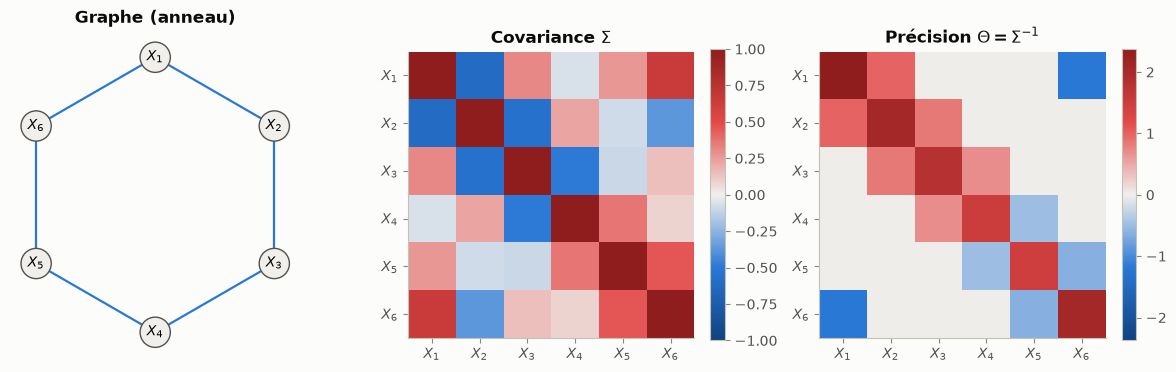

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
g.draw_graph(A_anneau, ax=axes[0], title="Graphe (anneau)")
for ax, M, t in [(axes[1], Sigma6, r"Covariance $\Sigma$"), (axes[2], Theta6, r"Précision $\Theta=\Sigma^{-1}$")]:
    v = np.abs(M).max()
    im = ax.imshow(M, cmap=DIV, vmin=-v, vmax=v)
    ax.set_title(t)
    ax.set_xticks(range(p), ["$X_%d$" % (j + 1) for j in range(p)])
    ax.set_yticks(range(p), ["$X_%d$" % (j + 1) for j in range(p)])
    ax.grid(False)
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

La covariance $\Sigma$ est **pleine** (toutes les variables sont corrélées via
l'anneau) alors que $\Theta$ est **creuse** : seules les arêtes de l'anneau (et la
diagonale) sont non nulles. Le graphe se lit sur $\Theta$, pas sur $\Sigma$.

> **Remarque.** Il existe un autre type de graphe, le *graphe de covariance* (ou
> réseau de pertinence), où l'on relie $j$ et $k$ si $\sigma_{jk} \neq 0$. Il code des
> indépendances **marginales** ; sa vraisemblance n'est pas concave, ce qui complique
> l'estimation. Nous n'en parlerons pas davantage.

### Corrélation partielle

La **corrélation partielle** de $X_j$ et $X_k$ sachant le reste est la corrélation de
la loi conditionnelle de $(X_j, X_k)$ sachant les autres variables. L'exercice 17.3
montre qu'elle vaut

$$
\rho_{jk\mid\text{reste}} = -\frac{\theta_{jk}}{\sqrt{\theta_{jj}\theta_{kk}}} .
$$

C'est une version « normalisée » de $\theta_{jk}$, sans unité, que nous utiliserons pour
représenter la force des arêtes.

In [14]:
R6 = g.partial_correlations(Theta6)
print("corrélations partielles le long de l'anneau :",
      np.round([R6[j, (j + 1) % p] for j in range(p)], 3))
print("corr. partielle empirique (X1, X2 | reste)   : %.3f" % corr_partielle(X6, 0, 1, range(2, p)))

corrélations partielles le long de l'anneau : [-0.45  -0.438 -0.417  0.326  0.362  0.533]


corr. partielle empirique (X1, X2 | reste)   : -0.447


## 5. Estimation à graphe connu (section 17.3.1)

### Log-vraisemblance

Soient $x_1, \dots, x_N$ i.i.d. de loi $\mathcal N_p(\mu, \Sigma)$, $\bar x$ leur moyenne et

$$
S = \frac1N\sum_{i=1}^N (x_i - \bar x)(x_i - \bar x)^T \qquad \text{(éq. (17.10))}
$$

la covariance empirique. La log-vraisemblance vaut

$$
\sum_{i=1}^N \log f(x_i) = -\frac{Np}{2}\log(2\pi) + \frac N2 \log\det\Theta
- \frac12\sum_{i=1}^N (x_i-\mu)^T\Theta(x_i-\mu).
$$

Pour tout $\Theta$ définie positive, la somme est minimale en $\mu = \bar x$
(décomposition $x_i - \mu = (x_i - \bar x) + (\bar x - \mu)$, le terme croisé est nul).

Ensuite, un nombre étant égal à sa trace et $\operatorname{tr}(AB) = \operatorname{tr}(BA)$ :

$$
\sum_{i}(x_i-\bar x)^T\Theta(x_i-\bar x) = \sum_i \operatorname{tr}\big(\Theta (x_i-\bar x)(x_i-\bar x)^T\big)
= N\operatorname{tr}(S\Theta).
$$

À constante et facteur $N/2$ près, la log-vraisemblance **profilée** (maximisée en
$\mu$) est donc (éq. (17.11))

$$
\ell(\Theta) = \log\det\Theta - \operatorname{tr}(S\Theta).
$$

**Deux outils de calcul différentiel matriciel.** On considère les $p^2$ coefficients
de $\Theta$ comme des variables.

1. $\partial \operatorname{tr}(S\Theta)/\partial\theta_{jk} = s_{kj}$ (fonction linéaire), donc le
   « gradient » de $\operatorname{tr}(S\Theta)$ est $S^T = S$.
2. $\partial\log\det\Theta/\partial\theta_{jk} = (\Theta^{-1})_{kj}$ : en développant
   $\det\Theta$ selon la ligne $j$, $\partial\det\Theta/\partial\theta_{jk}$ est le cofacteur
   $C_{jk}$, et $\Theta^{-1} = C^T/\det\Theta$.

Le gradient de $\ell$ est donc $\Theta^{-1} - S$ ; il s'annule pour $\Theta^{-1} = S$ :
**sans contrainte, l'estimateur du maximum de vraisemblance de $\Sigma$ est $S$.**

> **Concavité.** $\ell$ est concave : le long d'une droite $\Theta + tH$ (avec $H$
> symétrique), en notant $\lambda_i$ les valeurs propres de $\Theta^{-1/2}H\Theta^{-1/2}$,
> $\log\det(\Theta + tH) = \log\det\Theta + \sum_i \log(1 + t\lambda_i)$, somme de fonctions
> concaves de $t$, et la trace est linéaire. Tout point critique est donc un maximum
> global : c'est ce qui rend les algorithmes qui suivent fiables.

### Contraintes d'arêtes absentes et multiplicateurs de Lagrange

Si le graphe est imposé, on maximise $\ell$ sous les contraintes $\theta_{jk} = 0$ pour
$(j,k) \notin E$. On introduit un multiplicateur de Lagrange $\gamma_{jk}$ par contrainte
(éq. (17.12)) :

$$
\ell_C(\Theta) = \log\det\Theta - \operatorname{tr}(S\Theta) - \sum_{(j,k)\notin E}\gamma_{jk}\theta_{jk},
$$

dont l'équation de gradient est (éq. (17.13))

$$
\Theta^{-1} - S - \Gamma = 0,
$$

où $\Gamma$ est la matrice des $\gamma_{jk}$ (nuls sur les arêtes présentes et sur la
diagonale).

Notons $W = \Theta^{-1}$ (la covariance estimée par le modèle) et partageons, comme plus
haut, en partie 1 (les $p-1$ premières lignes/colonnes) et partie 2 (la dernière).
Le bloc en haut à droite de (17.13) donne (éq. (17.14))

$$
w_{12} - s_{12} - \gamma_{12} = 0 .
$$

Par ailleurs $W\Theta = I$ donne $W_{11}\theta_{12} + w_{12}\theta_{22} = 0$, donc
(éq. (17.16)–(17.17))

$$
w_{12} = -W_{11}\theta_{12}/\theta_{22} = W_{11}\beta, \qquad \beta = -\theta_{12}/\theta_{22}.
$$

En substituant (éq. (17.18)) :

$$
W_{11}\beta - s_{12} - \gamma_{12} = 0 .
$$

**Interprétation.** Ce sont les équations normales de la régression de $X_p$ sur les
autres variables (exercice 17.5), sauf que la matrice des produits croisés observés
$S_{11}$ est remplacée par $W_{11}$, la covariance **courante du modèle**.

Les lignes où $\gamma_{12}$ est non nul (arêtes absentes) ne portent aucune information
(on peut toujours choisir $\gamma$ pour les satisfaire) ; on les supprime, ainsi que
les coefficients de $\beta$ forcés à zéro. Il reste un système réduit (éq. (17.19)) :

$$
W_{11}^*\beta^* - s_{12}^* = 0 \quad\Longrightarrow\quad \hat\beta^* = (W^*_{11})^{-1}s^*_{12},
$$

qu'on complète par des zéros pour obtenir $\hat\beta$. Enfin, l'exercice 17.6 montre
que $1/\theta_{22} = w_{22} - w_{12}^T\beta$ (éq. (17.20)), et $w_{22} = s_{22}$ car la
diagonale de $\Gamma$ est nulle.

**Algorithme 17.1 (régressions modifiées, graphe connu).**

1. Initialiser $W = S$.
2. Répéter pour $j = 1, 2, \dots, p, 1, 2, \dots$ jusqu'à convergence :
   1. partager $W$ en partie 1 (tout sauf la ligne et colonne $j$) et partie 2 (la
      ligne et colonne $j$) ;
   2. résoudre $W_{11}^*\beta^* = s_{12}^*$ sur les seuls voisins de $j$, compléter
      $\hat\beta$ par des zéros ;
   3. mettre à jour $w_{12} = W_{11}\hat\beta$ (et symétriquement $w_{21}$).
3. Au dernier cycle, pour chaque $j$ : $\hat\theta_{22} = 1/(s_{22} - w_{12}^T\hat\beta)$ et
   $\hat\theta_{12} = -\hat\beta\,\hat\theta_{22}$.

Les $p$ régressions sont **couplées** par la matrice commune $W$ : c'est ce couplage
qui donne la solution exacte du maximum de vraisemblance contraint. L'implémentation
est `g.fit_known_graph`.

### L'exemple de la figure 17.4 (Whittaker)

Graphe : le carré $X_1 - X_2 - X_3 - X_4 - X_1$ (arêtes $(1,3)$ et $(2,4)$ absentes),
avec la covariance empirique donnée dans le livre.

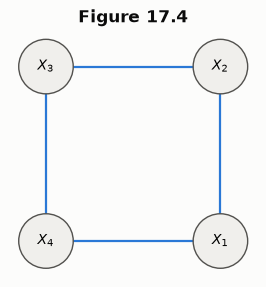

In [15]:
S4 = np.array([[10, 1, 5, 4],
               [1, 10, 2, 6],
               [5, 2, 10, 3],
               [4, 6, 3, 10.]])
A4 = g.adjacency_from_edges(4, [(0, 1), (1, 2), (2, 3), (3, 0)])
pos4 = np.array([[0.8, -0.8], [0.8, 0.8], [-0.8, 0.8], [-0.8, -0.8]])
fig, ax = plt.subplots(figsize=(3.2, 3.2))
g.draw_graph(A4, pos=pos4, ax=ax, node_size=0.25, title="Figure 17.4")
plt.show()

In [16]:
W4, Theta4, n_it = g.fit_known_graph(S4, A4, return_n_iter=True)
np.set_printoptions(precision=2, suppress=True)
print("Sigma chapeau (convergence en %d cycles) :\n" % n_it, W4)
print("Sigma chapeau ^-1 :\n", Theta4)
np.set_printoptions(precision=8, suppress=False)

Sigma chapeau (convergence en 4 cycles) :
 [[10.    1.    1.31  4.  ]
 [ 1.   10.    2.    0.87]
 [ 1.31  2.   10.    3.  ]
 [ 4.    0.87  3.   10.  ]]
Sigma chapeau ^-1 :
 [[ 0.12 -0.01 -0.   -0.05]
 [-0.01  0.1  -0.02 -0.  ]
 [-0.   -0.02  0.11 -0.03]
 [-0.05 -0.   -0.03  0.13]]


On retrouve les matrices du livre : les zéros de $\hat\Sigma^{-1}$ aux positions
$(1,3)$ et $(2,4)$, et $\hat\Sigma$ ne diffère de $S$ **qu'à ces positions**
($1{,}31$ au lieu de $5$, $0{,}87$ au lieu de $6$). $\hat\Sigma$ est la « complétion
définie positive » de $S$ compatible avec le graphe.

Suivons la convergence : écart maximal entre $W$ après $k$ cycles et la limite, et
log-vraisemblance $\ell(\hat\Theta)$ (on reconstruit $\hat\Theta = W^{-1}$).

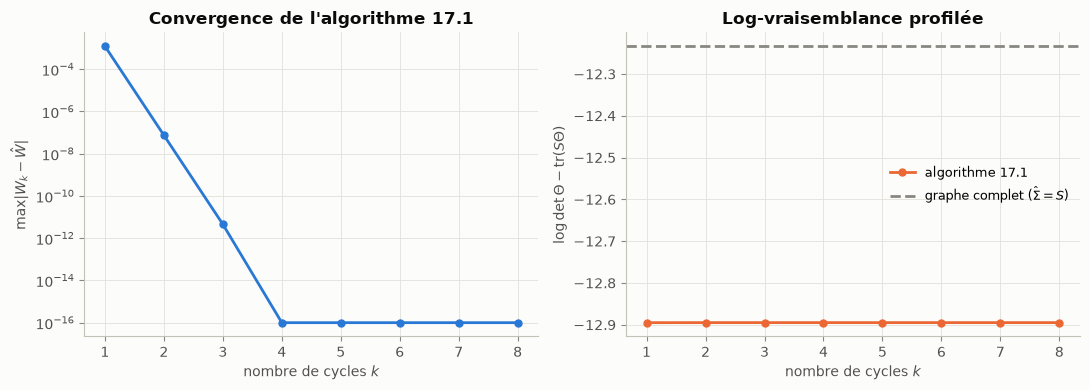

In [17]:
ecarts, logv = [], []
for k in range(1, 9):
    Wk, Tk = g.fit_known_graph(S4, A4, max_iter=k)
    ecarts.append(np.abs(Wk - W4).max())
    logv.append(g.gaussian_loglik(np.linalg.inv(Wk), S4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogy(range(1, 9), np.maximum(ecarts, 1e-16), "o-", color=BLUE)
axes[0].set(title="Convergence de l'algorithme 17.1", xlabel="nombre de cycles $k$",
            ylabel=r"$\max |W_k - \hat W|$")
axes[1].plot(range(1, 9), logv, "o-", color=ORANGE, label="algorithme 17.1")
axes[1].axhline(g.gaussian_loglik(np.linalg.inv(S4), S4), color=GRAY, ls="--",
                label="graphe complet ($\\hat\\Sigma = S$)")
axes[1].set(title="Log-vraisemblance profilée", xlabel="nombre de cycles $k$",
            ylabel=r"$\log\det\Theta - \mathrm{tr}(S\Theta)$")
axes[1].legend()
plt.tight_layout()
plt.show()

La convergence est géométrique et très rapide. La vraisemblance contrainte est
(logiquement) inférieure à celle du graphe complet : retirer des arêtes coûte un peu
de vraisemblance.

## 6. Estimation de la structure du graphe (section 17.3.2)

En général on ne connaît pas le graphe. On cherche une matrice $\hat\Theta$ **creuse**,
dont les zéros définiront le graphe estimé.

**Approche de Meinshausen et Bühlmann.** Pour chaque variable $j$, on fait une
régression lasso de $X_j$ sur les autres ; on déclare $\theta_{jk} \neq 0$ si le
coefficient de $k$ dans la régression de $j$ **ou** (variante : **et**) celui de $j$
dans la régression de $k$ est non nul. Simple, mais ne fournit qu'un graphe, pas
d'estimation de $\Sigma$ ni de $\Theta$.

**Graphical lasso.** Approche plus systématique : on maximise la log-vraisemblance
pénalisée (éq. (17.21))

$$
\log\det\Theta - \operatorname{tr}(S\Theta) - \lambda\|\Theta\|_1,
\qquad \|\Theta\|_1 = \sum_{j,k}|\theta_{jk}| .
$$

Comme pour le lasso (chapitre 3), la pénalité $\ell_1$ force certains coefficients à
être **exactement nuls**, et d'autant plus que $\lambda$ est grand. Le problème est
convexe (opposé d'une fonction concave plus une norme).

### Outil : sous-gradient de la valeur absolue

La fonction $t \mapsto |t|$ n'est pas dérivable en $0$. On la remplace par son
**sous-différentiel** :

$$
\operatorname{Sign}(t) = \begin{cases} \{\operatorname{sign}(t)\} & \text{si } t \neq 0,\\
[-1, 1] & \text{si } t = 0. \end{cases}
$$

Géométriquement, ce sont les pentes des droites passant par $(t, |t|)$ et situées
sous le graphe de $|\cdot|$. Pour une fonction convexe $F$, le point $t^\star$ est un
minimum si et seulement si $0$ appartient au sous-différentiel de $F$ en $t^\star$
(généralisation de « dérivée nulle »).

**Exemple fondamental (lasso à une variable).** Minimisons
$F(b) = \tfrac12 v b^2 - s b + \lambda|b|$ avec $v > 0$, $\lambda \geq 0$. La condition
d'optimalité est $0 \in v b - s + \lambda\operatorname{Sign}(b)$ :

- si $b > 0$ : $vb = s - \lambda$, possible seulement si $s > \lambda$ ;
- si $b < 0$ : $vb = s + \lambda$, possible seulement si $s < -\lambda$ ;
- si $b = 0$ : il faut $s \in [-\lambda, \lambda]$.

D'où $\hat b = \mathcal S(s, \lambda)/v$, où $\mathcal S(x,t) = \operatorname{sign}(x)(|x| - t)_+$
est l'opérateur de **seuillage doux** (éq. (17.27)).

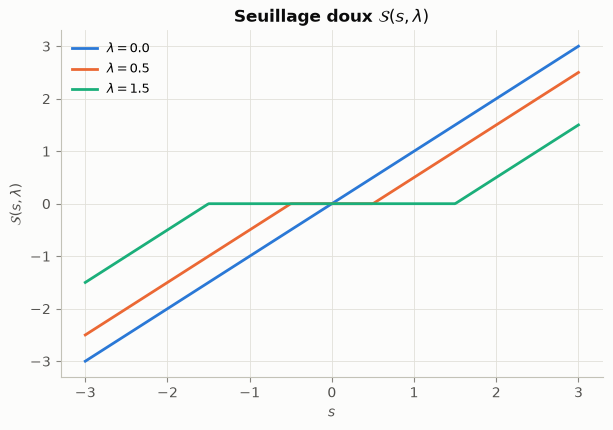

In [18]:
s_grid = np.linspace(-3, 3, 400)
fig, ax = plt.subplots(figsize=(7, 4.5))
for lam_, col in zip([0.0, 0.5, 1.5], COLORS):
    ax.plot(s_grid, g.soft_threshold(s_grid, lam_), color=col, label=r"$\lambda = %.1f$" % lam_)
ax.set(title="Seuillage doux $\\mathcal{S}(s, \\lambda)$", xlabel="$s$",
       ylabel="$\\mathcal{S}(s,\\lambda)$")
ax.legend()
plt.show()